# 04 — Árvore de Decisão

**Objetivo:** comparar critérios de impureza, ajustar hiperparâmetros com `GridSearchCV` (CV=5), demonstrar o *overfitting* da árvore sem restrição e interpretar a árvore final (visualização + 3 regras extraídas).

**Protocolo:** mesma divisão 80/20 (`random_state=42`), sem vazamento. Métricas da Aula 08.

In [1]:
import sys, json, os
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree
from sklearn.model_selection import GridSearchCV

from src.config import (
    SEED, CLASSIFICATION_TARGET, REGRESSION_TARGET, RISK_CLASSES,
    REPORTS_DIR, TABLES_DIR, FIGURES_DIR,
)
from src.data import split_train_test, encode_target
from src import metrics

np.random.seed(SEED)
sns.set_theme(style='whitegrid')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
(REPORTS_DIR / 'models').mkdir(parents=True, exist_ok=True)
(REPORTS_DIR / 'predictions').mkdir(parents=True, exist_ok=True)

MODELOS_DIR = REPORTS_DIR / 'models'
print('Semente:', SEED)

Semente: 42


## 1) Dados e divisão

A árvore não exige padronização: os cortes são monotônicos e invariantes à escala. Ainda assim, mantém-se exatamente a mesma divisão dos demais modelos.

In [2]:
df_reg = pd.read_csv('../data/processed/dataset_regression.csv')
df_clf = pd.read_csv('../data/processed/dataset_classification.csv')

Xr_train, Xr_test, yr_train, yr_test = split_train_test(df_reg, REGRESSION_TARGET, stratify=False)
Xc_train, Xc_test, yc_train_raw, yc_test_raw = split_train_test(df_clf, CLASSIFICATION_TARGET, stratify=True)
yc_train = encode_target(yc_train_raw)
yc_test = encode_target(yc_test_raw)

print('Treino:', Xc_train.shape, '| Teste:', Xc_test.shape)
print('Classes (treino):', yc_train.value_counts().sort_index().to_dict())

Treino: (40000, 85) | Teste: (10000, 85)
Classes (treino): {0: 20295, 1: 11824, 2: 7881}


## 2) Comparação de critérios de impureza

Classificação: `gini` vs `entropy`. Regressão: `squared_error`, `friedman_mse` e `absolute_error`. A comparação usa árvore sem poda para isolar o efeito do critério.

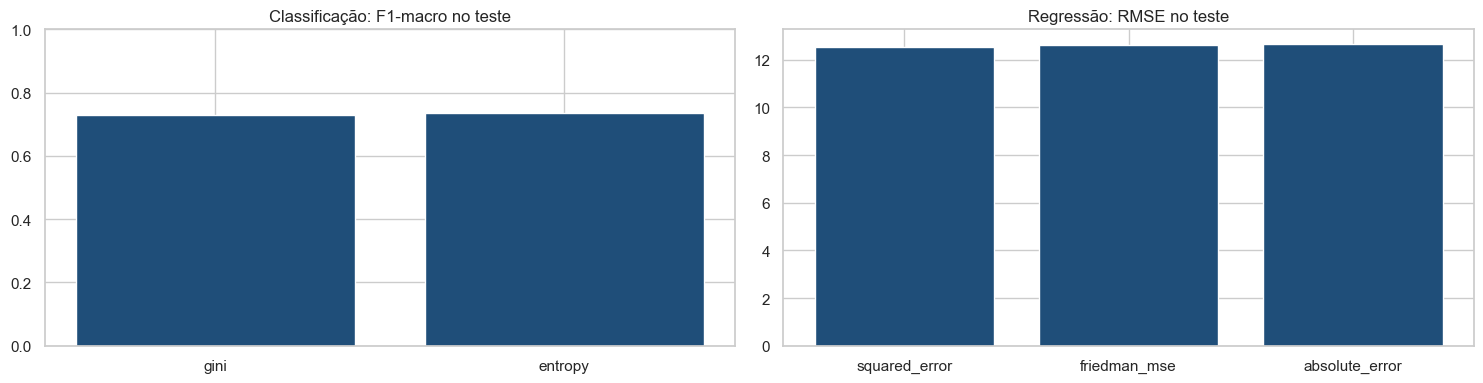

,Problema,Criterio,F1_macro_treino,F1_macro_teste,Accuracy_teste,Gap_F1,RMSE_treino,RMSE_teste,R2_teste,Gap_RMSE
0,Classificacao,gini,1.0,0.7299,0.7544,0.2701,NaN,NaN,NaN,NaN
1,Classificacao,entropy,1.0,0.7355,0.7604,0.2645,NaN,NaN,NaN,NaN
2,Regressao,squared_error,NaN,NaN,NaN,NaN,0.0,12.5399,0.7721,12.5399
3,Regressao,friedman_mse,NaN,NaN,NaN,NaN,0.0,12.6077,0.7696,12.6077
4,Regressao,absolute_error,NaN,NaN,NaN,NaN,0.0,12.6455,0.7683,12.6455


In [3]:
def avaliar_clf(modelo, nome):
    modelo.fit(Xc_train, yc_train)
    pred_tr = modelo.predict(Xc_train)
    pred_te = modelo.predict(Xc_test)
    proba_te = modelo.predict_proba(Xc_test)
    m_tr = metrics.classification_metrics(yc_train, pred_tr, proba_tr := modelo.predict_proba(Xc_train), classes=[0, 1, 2])
    m_te = metrics.classification_metrics(yc_test, pred_te, proba_te, classes=[0, 1, 2])
    m_tr['Modelo'] = m_te['Modelo'] = nome
    return m_tr, m_te

def avaliar_reg(modelo, nome):
    modelo.fit(Xr_train, yr_train)
    pred_tr = modelo.predict(Xr_train)
    pred_te = modelo.predict(Xr_test)
    m_tr = metrics.regression_metrics(yr_train, pred_tr)
    m_te = metrics.regression_metrics(yr_test, pred_te)
    m_tr['Modelo'] = m_te['Modelo'] = nome
    return m_tr, m_te

linhas = []
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for crit in ['gini', 'entropy']:
    m_tr, m_te = avaliar_clf(DecisionTreeClassifier(criterion=crit, random_state=SEED), f'Árvore ({crit})')
    gap = m_tr['F1 (macro)'] - m_te['F1 (macro)']
    linhas.append({'Problema': 'Classificacao', 'Criterio': crit,
                   'F1_macro_treino': m_tr['F1 (macro)'], 'F1_macro_teste': m_te['F1 (macro)'],
                   'Accuracy_teste': m_te['Accuracy'], 'Gap_F1': gap})
    axes[0].bar(crit, m_te['F1 (macro)'], color=['#1f4e79', '#c55a11'])
axes[0].set_title('Classificação: F1-macro no teste')
axes[0].set_ylim(0, 1)

for crit in ['squared_error', 'friedman_mse', 'absolute_error']:
    m_tr, m_te = avaliar_reg(DecisionTreeRegressor(criterion=crit, random_state=SEED), f'Árvore ({crit})')
    gap = m_te['RMSE'] - m_tr['RMSE']
    linhas.append({'Problema': 'Regressao', 'Criterio': crit,
                   'RMSE_treino': m_tr['RMSE'], 'RMSE_teste': m_te['RMSE'],
                   'R2_teste': m_te['R²'], 'Gap_RMSE': gap})
    axes[1].bar(crit, m_te['RMSE'], color=['#1f4e79', '#2e7d32', '#c55a11'])
axes[1].set_title('Regressão: RMSE no teste')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_comparacao_criterios.png', dpi=200, bbox_inches='tight')
plt.show()

comparacao_criterios = pd.DataFrame(linhas)
comparacao_criterios.to_csv(TABLES_DIR / '04_comparacao_criterios.csv', index=False)
comparacao_criterios.round(4)

## 3) Árvore sem restrição × árvore ajustada (overfitting)

A árvore sem `max_depth` memoriza o treino: F1 próximo de 1,0 no treino e muito menor no teste. O *gap* é a evidência numérica do overfitting.

In [4]:
arvore_livre_c = DecisionTreeClassifier(random_state=SEED)
arvore_livre_c.fit(Xc_train, yc_train)
pred_livre_tr = arvore_livre_c.predict(Xc_train)
pred_livre_te = arvore_livre_c.predict(Xc_test)

arvore_livre_r = DecisionTreeRegressor(random_state=SEED)
arvore_livre_r.fit(Xr_train, yr_train)
pred_livre_r_tr = arvore_livre_r.predict(Xr_train)
pred_livre_r_te = arvore_livre_r.predict(Xr_test)

overfit = pd.DataFrame([
    {'Problema': 'Classificacao', 'Modelo': 'Árvore sem restrição',
     'F1_macro_treino': metrics.classification_metrics(yc_train, pred_livre_tr)['F1 (macro)'],
     'F1_macro_teste': metrics.classification_metrics(yc_test, pred_livre_te)['F1 (macro)'],
     'Profundidade': arvore_livre_c.get_depth(), 'Folhas': arvore_livre_c.get_n_leaves()},
    {'Problema': 'Regressao', 'Modelo': 'Árvore sem restrição',
     'RMSE_treino': metrics.regression_metrics(yr_train, pred_livre_r_tr)['RMSE'],
     'RMSE_teste': metrics.regression_metrics(yr_test, pred_livre_r_te)['RMSE'],
     'Profundidade': arvore_livre_r.get_depth(), 'Folhas': arvore_livre_r.get_n_leaves()},
])
overfit['Gap'] = overfit['F1_macro_treino'] - overfit['F1_macro_teste']
overfit.loc[overfit['Problema'] == 'Regressao', 'Gap'] = (
    overfit.loc[overfit['Problema'] == 'Regressao', 'RMSE_teste']
    - overfit.loc[overfit['Problema'] == 'Regressao', 'RMSE_treino']
)
overfit.to_csv(TABLES_DIR / '04_arvore_sem_restricao.csv', index=False)
overfit.round(4)

,Problema,Modelo,F1_macro_treino,F1_macro_teste,Profundidade,Folhas,RMSE_treino,RMSE_teste,Gap
0,Classificacao,Árvore sem restrição,1.0,0.7299,30,4360,NaN,NaN,0.2701
1,Regressao,Árvore sem restrição,NaN,NaN,41,31638,0.0,12.5399,12.5399


## 4) Ajuste de hiperparâmetros com `GridSearchCV` (CV=5)

Grade propositalmente enxuta (orçamento computacional): `max_depth`, `min_samples_leaf` e `ccp_alpha` (poda por complexidade). Métrica de seleção: **F1-macro** na classificação e **RMSE negativo** na regressão. Reporta-se a média e o desvio-padrão dos 5 folds.

In [5]:
grade = {
    'max_depth': [6, 10, 15],
    'min_samples_leaf': [5, 10],
    'ccp_alpha': [0.0, 0.001],
}

busca_c = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    grade, cv=5, scoring='f1_macro', n_jobs=4, return_train_score=True,
)
busca_c.fit(Xc_train, yc_train)

busca_r = GridSearchCV(
    DecisionTreeRegressor(random_state=SEED),
    grade, cv=5, scoring='neg_root_mean_squared_error', n_jobs=4, return_train_score=True,
)
busca_r.fit(Xr_train, yr_train)

print('Classificação — melhores parâmetros:', busca_c.best_params_)
print('F1-macro CV (média ± dp): {:.4f} ± {:.4f}'.format(
    busca_c.best_score_, busca_c.cv_results_['std_test_score'][busca_c.best_index_]))
print('\nRegressão — melhores parâmetros:', busca_r.best_params_)
print('RMSE CV (média): {:.4f} | dp: {:.4f}'.format(
    -busca_r.best_score_, busca_r.cv_results_['std_test_score'][busca_r.best_index_]))

Classificação — melhores parâmetros: {'ccp_alpha': 0.0, 'max_depth': 6, 'min_samples_leaf': 10}
F1-macro CV (média ± dp): 0.7875 ± 0.0060

Regressão — melhores parâmetros: {'ccp_alpha': 0.0, 'max_depth': 6, 'min_samples_leaf': 5}
RMSE CV (média): 9.1696 | dp: 0.0458


In [6]:
# Tabela com os melhores resultados da validação cruzada (média e dp dos folds)
def resumo_busca(busca, problema):
    idx = busca.best_index_
    return {
        'Problema': problema,
        'Melhores_parametros': json.dumps({k: (v.item() if hasattr(v, 'item') else v) for k, v in busca.best_params_.items()}),
        'Metrica_CV': 'F1-macro' if problema == 'Classificacao' else 'RMSE',
        'Media_CV': float(busca.best_score_ if problema == 'Classificacao' else -busca.best_score_),
        'Desvio_padrao_CV': float(busca.cv_results_['std_test_score'][idx]),
        'Media_treino_CV': float(busca.cv_results_['mean_train_score'][idx]),
    }

cv_resumo = pd.DataFrame([resumo_busca(busca_c, 'Classificacao'), resumo_busca(busca_r, 'Regressao')])
cv_resumo.to_csv(TABLES_DIR / '04_gridsearch_cv.csv', index=False)
cv_resumo.round(4)

,Problema,Melhores_parametros,Metrica_CV,Media_CV,Desvio_padrao_CV,Media_treino_CV
0,Classificacao,"{""ccp_alpha"": 0.0, ""max_depth"": 6, ""min_sample...",F1-macro,0.7875,0.0060,0.7952
1,Regressao,"{""ccp_alpha"": 0.0, ""max_depth"": 6, ""min_sample...",RMSE,9.1696,0.0458,-9.0264


## 5) Árvore final: métricas, gap e matriz de confusão

A árvore final é o `best_estimator_` da busca. O *gap* é calculado com os valores **exatos** (sem arredondar antes da subtração).

In [7]:
arvore_c = busca_c.best_estimator_
arvore_r = busca_r.best_estimator_

pred_c_tr = arvore_c.predict(Xc_train)
pred_c_te = arvore_c.predict(Xc_test)
proba_c_tr = arvore_c.predict_proba(Xc_train)
proba_c_te = arvore_c.predict_proba(Xc_test)

pred_r_tr = arvore_r.predict(Xr_train)
pred_r_te = arvore_r.predict(Xr_test)

m_c_tr = metrics.classification_metrics(yc_train, pred_c_tr, proba_c_tr, classes=[0, 1, 2])
m_c_te = metrics.classification_metrics(yc_test, pred_c_te, proba_c_te, classes=[0, 1, 2])
m_r_tr = metrics.regression_metrics(yr_train, pred_r_tr)
m_r_te = metrics.regression_metrics(yr_test, pred_r_te)

print('CLASSIFICAÇÃO — treino × teste')
display(pd.DataFrame([m_c_tr, m_c_te], index=['Treino', 'Teste']).round(4))
print('Gap F1-macro:', round(m_c_tr['F1 (macro)'] - m_c_te['F1 (macro)'], 6))

print('\nREGRESSÃO — treino × teste')
display(pd.DataFrame([m_r_tr, m_r_te], index=['Treino', 'Teste']).round(4))
print('Gap RMSE:', round(m_r_te['RMSE'] - m_r_tr['RMSE'], 6))

CLASSIFICAÇÃO — treino × teste


,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC (OVR macro),PR-AUC (macro)
Treino,0.8103,0.8062,0.7808,0.7903,0.8174,0.8103,0.8118,0.9435,0.8536
Teste,0.8096,0.8066,0.7798,0.7899,0.8167,0.8096,0.8110,0.9417,0.8498


Gap F1-macro: 0.000448

REGRESSÃO — treino × teste


,MAE,MSE,RMSE,MAPE (%),R²,MedAE,Cobertura MAPE (%)
Treino,7.6301,81.7267,9.0403,36.7000,0.8810,6.9735,93.11
Teste,7.7679,83.9369,9.1617,39.0485,0.8784,7.2214,93.00


Gap RMSE: 0.121429


In [8]:
cm = metrics.confusion_matrix_frame(yc_test, pred_c_te, classes=RISK_CLASSES)
per_class = metrics.per_class_report(yc_test, pred_c_te, classes=RISK_CLASSES)
cm.to_csv(TABLES_DIR / '04_matriz_confusao_arvore.csv', index=False)
per_class.to_csv(TABLES_DIR / '04_por_classe_arvore.csv', index=False)
display(cm)
display(per_class.round(4))

,,Prev. Low,Prev. Moderate,Prev. High
0,Real Low,4516,558,0
1,Real Moderate,580,2173,203
2,Real High,3,560,1407


,Classe,Suporte,Precision,Recall,F1
0,Low,5074,0.8857,0.8900,0.8878
1,Moderate,2956,0.6603,0.7351,0.6957
2,High,1970,0.8739,0.7142,0.7860


## 6) Visualização da árvore final e extração de 3 regras

A árvore completa é profunda; para leitura, plota-se até a profundidade 3. Em seguida, um algoritmo percorre a estrutura real da árvore e extrai os caminhos até as folhas com maior suporte — essas são as 3 regras interpretadas.

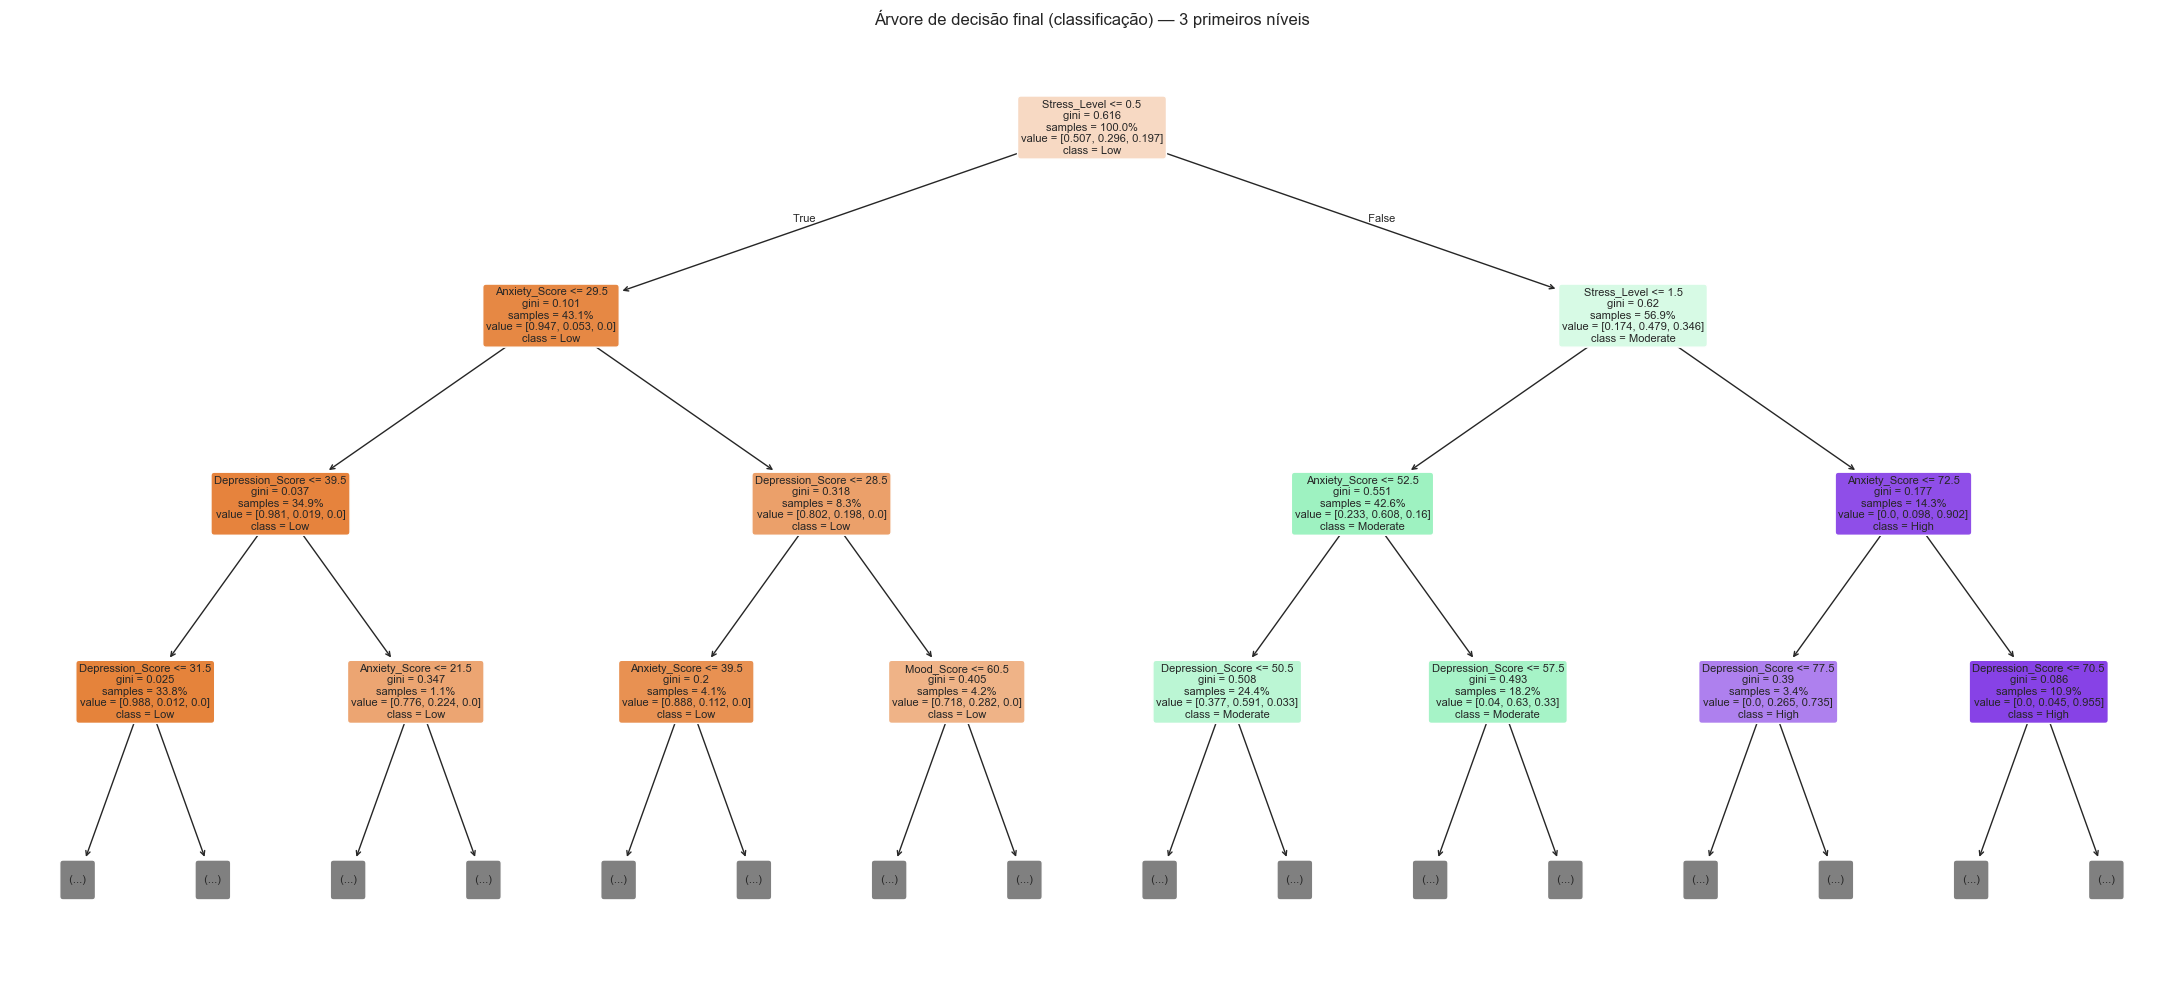

In [9]:
plt.figure(figsize=(22, 10))
plot_tree(
    arvore_c, max_depth=3, feature_names=Xc_train.columns.tolist(),
    class_names=RISK_CLASSES, filled=True, rounded=True, proportion=True, fontsize=8,
)
plt.title('Árvore de decisão final (classificação) — 3 primeiros níveis')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_arvore_classificacao.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
def extrair_regras(arvore, feature_names, classes=None, max_regras=3):
    """Extrai regras SE-ENTÃO dos caminhos até as folhas com mais amostras.

    Condições repetidas sobre a mesma variável são simplificadas: para '<='
    mantém-se o menor limiar e para '>' o maior (o corte mais restritivo).
    """
    import re
    tree = arvore.tree_
    regras = []

    def simplificar(condicoes):
        ordem = []
        limites = {}
        for condicao in condicoes:
            achado = re.match(r'(.+) (<=|>) ([0-9.]+)', condicao)
            if not achado:
                continue
            feature, operador, valor = achado.group(1), achado.group(2), float(achado.group(3))
            chave = (feature, operador)
            if feature not in ordem:
                ordem.append(feature)
            if chave not in limites:
                limites[chave] = valor
            elif operador == '<=':
                limites[chave] = min(limites[chave], valor)
            else:
                limites[chave] = max(limites[chave], valor)
        simples = []
        for feature in ordem:
            for operador in ['<=', '>']:
                if (feature, operador) in limites:
                    simples.append(f'{feature} {operador} {limites[(feature, operador)]:.2f}')
        return simples

    def percorrer(no, condicoes):
        if tree.children_left[no] == tree.children_right[no]:
            valores = tree.value[no][0]
            total = valores.sum()
            if classes is not None:
                conclusao = classes[int(np.argmax(valores))]
                distribuicao = {classes[i]: round(float(v / total), 3) for i, v in enumerate(valores)}
            else:
                conclusao = round(float(valores[0]), 2)
                distribuicao = None
            regras.append({
                'condicoes': simplificar(condicoes),
                'conclusao': conclusao,
                'amostras': int(tree.n_node_samples[no]),
                'distribuicao': distribuicao,
            })
            return

        feature = feature_names[tree.feature[no]]
        limiar = tree.threshold[no]
        percorrer(tree.children_left[no], condicoes + [f'{feature} <= {limiar:.2f}'])
        percorrer(tree.children_right[no], condicoes + [f'{feature} > {limiar:.2f}'])

    percorrer(0, [])
    regras.sort(key=lambda r: r['amostras'], reverse=True)
    return regras[:max_regras]

regras_arvore = extrair_regras(arvore_c, Xc_train.columns.tolist(), classes=RISK_CLASSES, max_regras=3)
for i, regra in enumerate(regras_arvore, start=1):
    print(f'REGRA-{i:02d} (n={regra["amostras"]}, distribuição={regra["distribuicao"]})')
    print('SE ' + ' E '.join(regra['condicoes']))
    print('ENTÃO Burnout_Risk =', regra['conclusao'], '\n')

with open(TABLES_DIR / '04_regras_arvore.txt', 'w', encoding='utf-8') as f:
    for i, regra in enumerate(regras_arvore, start=1):
        f.write(f'REGRA-{i:02d} (n={regra["amostras"]})\n')
        f.write('SE ' + ' E '.join(regra['condicoes']) + '\n')
        f.write(f'ENTÃO Burnout_Risk = {regra["conclusao"]}\n')
        f.write(f'Distribuição na folha: {regra["distribuicao"]}\n\n')

REGRA-01 (n=10192, distribuição={'Low': 0.999, 'Moderate': 0.001, 'High': 0.0})
SE Stress_Level <= 0.50 E Anxiety_Score <= 29.50 E Depression_Score <= 31.50 E Mood_Score > 75.50 E Emotional_Stability > 64.50
ENTÃO Burnout_Risk = Low 

REGRA-02 (n=2785, distribuição={'Low': 0.0, 'Moderate': 0.008, 'High': 0.992})
SE Stress_Level > 1.50 E Anxiety_Score > 79.50 E Depression_Score > 70.50 E Chronic_Stress > 0.50
ENTÃO Burnout_Risk = High 

REGRA-03 (n=2382, distribuição={'Low': 0.429, 'Moderate': 0.57, 'High': 0.002})
SE Stress_Level <= 1.50 E Stress_Level > 0.50 E Anxiety_Score <= 52.50 E Anxiety_Score > 40.50 E Depression_Score <= 50.50 E Mood_Score > 51.50
ENTÃO Burnout_Risk = Moderate 



## 7) Importância das variáveis

A importância por impureza (`feature_importances_`) indica quais variáveis mais reduzem a impureza nos cortes. Compara-se com as variáveis usadas nas regras do sistema especialista.

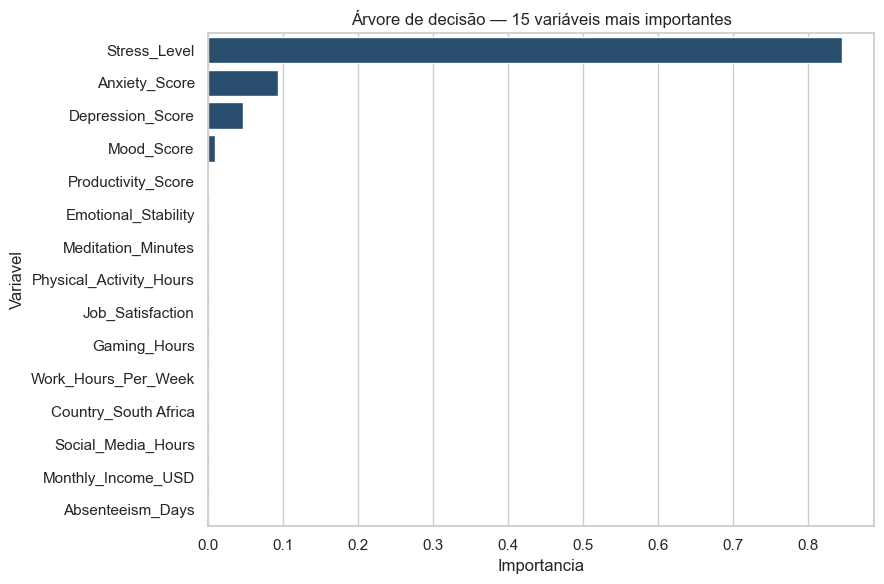

,Variavel,Importancia
8,Stress_Level,0.8456
9,Anxiety_Score,0.0931
10,Depression_Score,0.0466
11,Mood_Score,0.0097
28,Productivity_Score,0.0008
12,Emotional_Stability,0.0006
15,Meditation_Minutes,0.0005
13,Physical_Activity_Hours,0.0005
4,Job_Satisfaction,0.0004
18,Gaming_Hours,0.0003


In [11]:
importancias = pd.DataFrame({
    'Variavel': Xc_train.columns,
    'Importancia': arvore_c.feature_importances_,
}).sort_values('Importancia', ascending=False)
importancias.to_csv(TABLES_DIR / '04_importancia_arvore.csv', index=False)

top15 = importancias.head(15)
plt.figure(figsize=(9, 6))
sns.barplot(data=top15, x='Importancia', y='Variavel', color='#1f4e79')
plt.title('Árvore de decisão — 15 variáveis mais importantes')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_importancia_arvore.png', dpi=200, bbox_inches='tight')
plt.show()
top15.round(4)

## 8) Persistência do modelo, predições e tamanho em disco

O modelo é salvo com `joblib` para ser reutilizado nos notebooks 06 e 07. O tamanho em disco é medido em KB.

In [12]:
joblib.dump(arvore_c, MODELOS_DIR / 'tree_classificacao.joblib', compress=3)
joblib.dump(arvore_r, MODELOS_DIR / 'tree_regressao.joblib', compress=3)

tamanho_c = os.path.getsize(MODELOS_DIR / 'tree_classificacao.joblib') / 1024
tamanho_r = os.path.getsize(MODELOS_DIR / 'tree_regressao.joblib') / 1024
print(f'Tamanho em disco — classificação: {tamanho_c:.2f} KB | regressão: {tamanho_r:.2f} KB')

np.savez(REPORTS_DIR / 'predictions' / 'tree_classificacao.npz',
         y_true_test=yc_test.values, y_pred_test=pred_c_te, y_proba_test=proba_c_te,
         y_true_train=yc_train.values, y_pred_train=pred_c_tr, y_proba_train=proba_c_tr)
np.savez(REPORTS_DIR / 'predictions' / 'tree_regressao.npz',
         y_true_test=yr_test.values, y_pred_test=pred_r_te,
         y_true_train=yr_train.values, y_pred_train=pred_r_tr)

parametros = {
    'classificacao': {k: (v.item() if hasattr(v, 'item') else v) for k, v in busca_c.best_params_.items()},
    'regressao': {k: (v.item() if hasattr(v, 'item') else v) for k, v in busca_r.best_params_.items()},
    'tamanho_disco_kb': {'classificacao': tamanho_c, 'regressao': tamanho_r},
    'profundidade': {'classificacao': int(arvore_c.get_depth()), 'regressao': int(arvore_r.get_depth())},
    'folhas': {'classificacao': int(arvore_c.get_n_leaves()), 'regressao': int(arvore_r.get_n_leaves())},
    'cv': {'classificacao': {'media': float(busca_c.best_score_), 'dp': float(busca_c.cv_results_['std_test_score'][busca_c.best_index_])},
           'regressao': {'media': float(-busca_r.best_score_), 'dp': float(busca_r.cv_results_['std_test_score'][busca_r.best_index_])}},
}
(MODELOS_DIR / 'tree_params.json').write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding='utf-8')

Tamanho em disco — classificação: 6.37 KB | regressão: 5.17 KB


616

In [13]:
# Resultados consolidados do modelo (treino/teste)
linhas = []
for split, mc, mr in [('Treino', m_c_tr, m_r_tr), ('Teste', m_c_te, m_r_te)]:
    for problema, m in [('Classificacao', mc), ('Regressao', mr)]:
        linha = {'Familia': 'Arvore de Decisao', 'Modelo': 'DecisionTree ajustada',
                 'Problema': problema, 'Conjunto': split}
        linha.update({k: v for k, v in m.items() if k != 'Modelo'})
        linhas.append(linha)

resultados = pd.DataFrame(linhas)
resultados.to_csv(TABLES_DIR / 'resultados_arvore.csv', index=False)
resultados.round(4).to_string(index=False)

'          Familia                Modelo      Problema Conjunto  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Precision (weighted)  Recall (weighted)  F1 (weighted)  ROC-AUC (OVR macro)  PR-AUC (macro)    MAE     MSE   RMSE  MAPE (%)     R²  MedAE  Cobertura MAPE (%)\nArvore de Decisao DecisionTree ajustada Classificacao   Treino    0.8103             0.8062          0.7808      0.7903                0.8174             0.8103         0.8118               0.9435          0.8536    NaN     NaN    NaN       NaN    NaN    NaN                 NaN\nArvore de Decisao DecisionTree ajustada     Regressao   Treino       NaN                NaN             NaN         NaN                   NaN                NaN            NaN                  NaN             NaN 7.6301 81.7267 9.0403   36.7000 0.8810 6.9735               93.11\nArvore de Decisao DecisionTree ajustada Classificacao    Teste    0.8096             0.8066          0.7798      0.7899                0.8167             0.809

## 9) Interpretação

- **Overfitting:** a árvore sem restrição atinge F1 ~1,0 no treino e cai no teste; o *gap* elevado confirma o fenômeno.
- **Poda:** `max_depth`, `min_samples_leaf` e `ccp_alpha` reduzem o *gap* e mantêm o desempenho.
- **Interpretabilidade:** as 3 regras extraídas usam as mesmas variáveis do sistema especialista (ansiedade, depressão, humor, estabilidade emocional, produtividade e jornada), mas com limiares aprendidos dos dados.
- **Custo:** árvore pequena em disco e muito rápida na inferência (medida no notebook 07).